# Unsupervised Learning

PCA and K-Means++ explore the pre-collapse properties. The weighted score is used afterward to describe the results.

In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [113]:
RANDOM_SEED = 42

## Load Gold

Each row represents one progenitor. I keep `model` and `target_score` aside because they are not input features for the unsupervised methods.

In [114]:
gold = pd.read_csv("../data/gold/progenitor_gold.csv")
print(f"Gold: {gold.shape[0]} rows, {gold.shape[1]} columns")
display(gold[["model", "target_score"]].sample(5, random_state=RANDOM_SEED))

Gold: 187 rows, 46 columns


,model,target_score
185,s100,0.5
78,s20.5,0.0
55,s18.2,0.0
137,s26.4,0.2
161,s28.8,1.0


In [115]:
models = gold["model"]
target_scores = gold["target_score"]
features = gold.drop(columns=["model", "target_score"])

## Standardize features

The features use different units and scales. I standardize them before PCA and distance-based clustering.

In [116]:
scaler = StandardScaler()
scaled_features = pd.DataFrame(
    scaler.fit_transform(features),
    columns=features.columns,
)
display(scaled_features.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
zams_mass_msun,187.0,-0.0,1.0,-0.92,-0.52,-0.15,0.22,7.61
central_a_bar,187.0,-0.0,1.0,-2.71,-0.39,0.22,0.81,1.27
central_density_g_cm3,187.0,0.0,1.0,-2.03,-0.64,0.03,0.74,2.42
central_entropy,187.0,0.0,1.0,-1.34,-0.83,-0.22,0.33,2.64
central_log10_density,187.0,0.0,1.0,-3.02,-0.48,0.21,0.77,1.76
central_log10_temperature,187.0,-0.0,1.0,-6.56,-0.67,0.11,0.62,1.56
central_temperature_k,187.0,0.0,1.0,-5.93,-0.70,0.10,0.63,1.64
central_y_e,187.0,-0.0,1.0,-2.12,-0.86,-0.10,0.50,2.12
co_core_mass_msun,187.0,-0.0,1.0,-1.63,-0.85,-0.02,0.74,3.47
entropy_at_1p5_msun,187.0,-0.0,1.0,-0.96,-0.60,-0.31,0.02,3.15


## Covariance after scaling

This heatmap shows the covariance of eight selected features. PCA uses all 44 features.

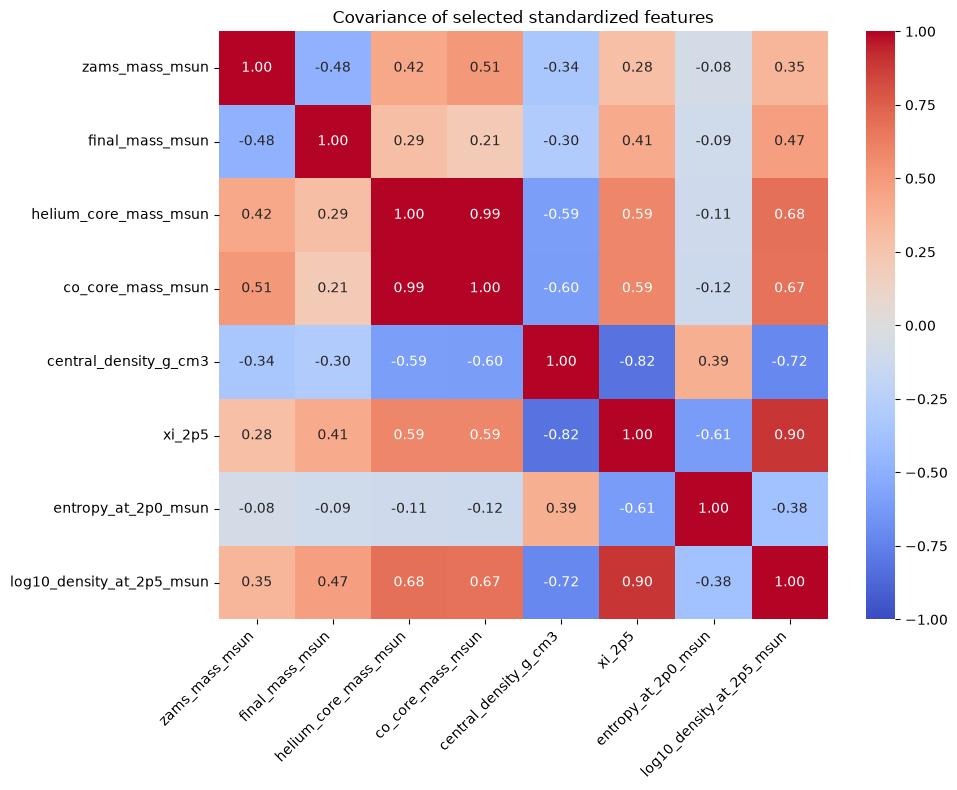

In [117]:
covariance_features = [
    "zams_mass_msun",
    "final_mass_msun",
    "helium_core_mass_msun",
    "co_core_mass_msun",
    "central_density_g_cm3",
    "xi_2p5",
    "entropy_at_2p0_msun",
    "log10_density_at_2p5_msun",
]
covariance_matrix = scaled_features[covariance_features].cov(ddof=0)

plt.figure(figsize=(10, 8))
sns.heatmap(covariance_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Covariance of selected standardized features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Helium core mass and CO core mass move closely together (0.99). Core compactness and density at 2.5 solar masses also move together (0.90), while central density tends to move in the opposite direction to compactness (-0.82). Since the features were standardized, these covariances are effectively correlations.

## PCA

PCA uses the 44 standardized features. The explained variance shows how much information each component retains.

In [118]:
pca = PCA()
pca.fit(scaled_features)

explained_variance = pd.DataFrame({
    "component": range(1, len(pca.explained_variance_ratio_) + 1),
    "explained_variance": pca.explained_variance_ratio_,
    "cumulative_variance": pca.explained_variance_ratio_.cumsum(),
})
display(explained_variance.head(10).round(3))

first_four_variance = pca.explained_variance_ratio_[:4].sum()
print(f"First four components explain {first_four_variance:.1%} of variance")
components_for_90 = (explained_variance["cumulative_variance"] < 0.90).sum() + 1
print(f"Components needed for 90% explained variance: {components_for_90}")

,component,explained_variance,cumulative_variance
0,1,0.474,0.474
1,2,0.160,0.634
2,3,0.138,0.772
3,4,0.063,0.835
4,5,0.033,0.868
5,6,0.029,0.896
6,7,0.022,0.918
7,8,0.016,0.935
8,9,0.016,0.950
9,10,0.008,0.958


First four components explain 83.5% of variance
Components needed for 90% explained variance: 7


The first four components retain 83.5% of the variation in the features.

## PCA projection

The first two components retain 63.4% of the feature variance. PCA was fitted without `target_score`; the colors show the weighted scores afterward.

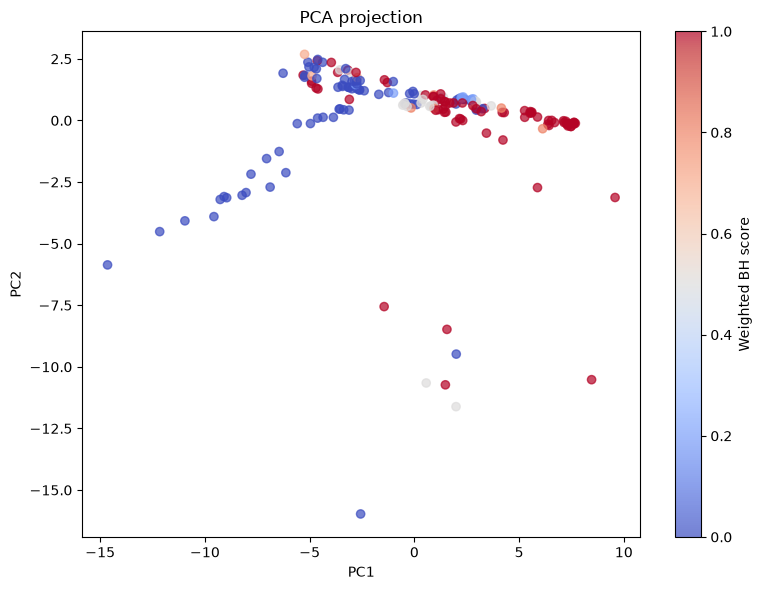

In [119]:
pca_coordinates = pca.transform(scaled_features)
plt.figure(figsize=(8, 6))
points = plt.scatter(pca_coordinates[:, 0], pca_coordinates[:, 1], c=target_scores, cmap="coolwarm", vmin=0, vmax=1, alpha=0.7)
plt.colorbar(points, label="Weighted BH score")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA projection")
plt.tight_layout()
plt.show()

Lower PC1 values mostly coincide with NS consensus, while higher values more often coincide with BH consensus. The balance changes around PC1 = -2.5, but the scores still overlap. PC2 does not show a clear pattern with the score.

## K-Means++

K-Means++ uses all 44 standardized features. Silhouette and the size of the smallest group are compared for `k` from 2 to 10. The PCA projection shows the groups in two dimensions.

In [120]:
results = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_SEED)
    labels = kmeans.fit_predict(scaled_features)
    cluster_sizes = []
    for cluster in range(k):
        cluster_sizes.append((labels == cluster).sum())
    results.append({
        "k": k,
        "silhouette": silhouette_score(scaled_features, labels),
        "smallest_cluster_size": min(cluster_sizes),
    })

silhouette_results = pd.DataFrame(results)
display(silhouette_results.sort_values("silhouette", ascending=False).round(3))

,k,silhouette,smallest_cluster_size
4,6,0.438,1
5,7,0.438,1
3,5,0.436,8
2,4,0.412,8
8,10,0.379,1
6,8,0.377,1
1,3,0.376,14
0,2,0.368,76
7,9,0.358,1


Silhouette is similar for `k=5`, `k=6` and `k=7` (0.436–0.438). With six or seven groups, one progenitor ends up alone.

### Inspecting five clusters

With five groups, silhouette is almost as high as with six or seven, and the smallest group has eight stars. The cluster numbers are arbitrary labels.

In [121]:
chosen_k = 5
kmeans = KMeans(n_clusters=chosen_k, init="k-means++", n_init=10, random_state=RANDOM_SEED)
cluster_labels = kmeans.fit_predict(scaled_features)

cluster_summary = []
for cluster in range(chosen_k):
    members = gold[cluster_labels == cluster]
    scores = members["target_score"]
    cluster_summary.append({
        "cluster": cluster,
        "progenitors": len(members),
        "NS_consensus": (scores == 0).sum(),
        "BH_consensus": (scores == 1).sum(),
        "mixed": ((scores > 0) & (scores < 1)).sum(),
        "mean_target_score": scores.mean(),
    })

display(pd.DataFrame(cluster_summary).round(2))


,cluster,progenitors,NS_consensus,BH_consensus,mixed,mean_target_score
0,0,58,39,13,6,0.28
1,1,32,0,31,1,0.99
2,2,14,14,0,0,0.00
3,3,8,2,4,2,0.62
4,4,75,19,27,29,0.55


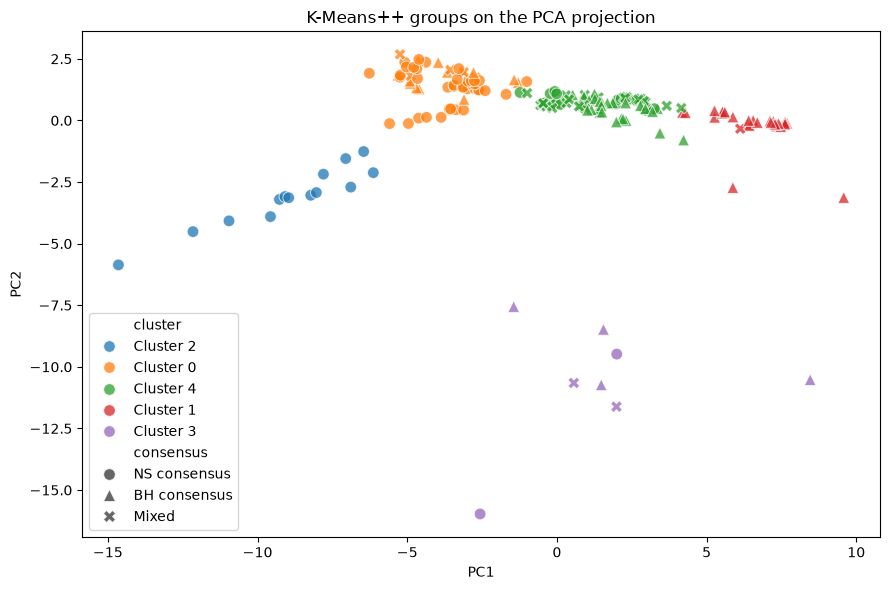

In [122]:
consensus = []
for score in target_scores:
    if score == 0:
        consensus.append("NS consensus")
    elif score == 1:
        consensus.append("BH consensus")
    else:
        consensus.append("Mixed")

plot_data = pd.DataFrame({
    "PC1": pca_coordinates[:, 0],
    "PC2": pca_coordinates[:, 1],
    "cluster": [f"Cluster {label}" for label in cluster_labels],
    "consensus": consensus,
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_data, x="PC1", y="PC2", hue="cluster", style="consensus",
    markers={"NS consensus": "o", "BH consensus": "^", "Mixed": "X"},
    s=70, alpha=0.75,
)
plt.title("K-Means++ groups on the PCA projection")
plt.tight_layout()
plt.show()


Colors show the five clusters. Circles have unanimous NS outcomes, triangles have unanimous BH outcomes and crosses have mixed engine outcomes. Cluster 1 has 31 of 32 progenitors with unanimous BH outcomes, while all 14 in cluster 2 have unanimous NS outcomes. Cluster 0 mostly contains unanimous NS outcomes. Clusters 3 and 4 are more mixed. The outcomes were used only to describe the groups after clustering.

## Conclusion

The EDA found 149 progenitors with unanimous engine outcomes and 38 with disagreement. It examined eight pre-collapse properties in detail. In this notebook, the first two PCA components retain 63.4% of the variation in all 44 features. With five K-Means++ groups, one group is almost entirely BH consensus and another is entirely NS consensus. The remaining groups contain a mix of scores.

The other 36 features were kept in Gold but were not examined one by one. PCA and K-Means++ show structure in the data, but they do not measure how well the outcome can be predicted for new stars. That is the next step in the supervised analysis.